# Practical Session 4 — Overfitting, data leakage and model generalization
Dataset: `hybrid_student_performance_1200.csv` — target: `final_cgpa` (regression).
Fixed seed `42`; one chronological split (first 80 % train / last 20 % test) reused from Part B onward; every preprocessing step lives inside a `Pipeline`.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, TimeSeriesSplit
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (OneHotEncoder, TargetEncoder,
                                   PolynomialFeatures, StandardScaler)
from sklearn.tree import DecisionTreeRegressor

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

# Part A — Data inspection and potential leakage
## A.1 Dimensions, types, missing values

In [2]:
df_raw = pd.read_csv("hybrid_student_performance_1200.csv")
print("Shape:", df_raw.shape)
df_raw.info()

Shape: (1200, 36)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 36 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   student_id              1200 non-null   object 
 1   timestamp               1200 non-null   object 
 2   year_class              1200 non-null   object 
 3   program_stream          1200 non-null   object 
 4   age                     1200 non-null   int64  
 5   gender                  1200 non-null   object 
 6   cgpa_category           1200 non-null   object 
 7   academic_satisfaction   1200 non-null   object 
 8   study_hours_daily       1200 non-null   object 
 9   daily_productivity      1166 non-null   float64
 10  revision_frequency      1166 non-null   object 
 11  focus_duration          1157 non-null   object 
 12  screen_time_non_study   1168 non-null   object 
 13  main_distractor         1200 non-null   object 
 14  study_consistency     

In [3]:
missing = df_raw.isnull().sum()
missing_summary = pd.DataFrame({
    "Missing values": missing,
    "Missing %": (missing / len(df_raw) * 100).round(2)
})
missing_summary[missing_summary["Missing values"] > 0].sort_values("Missing %", ascending=False)

,Missing values,Missing %
events_participation,58,4.83
sleep_hours,55,4.58
external_resources,45,3.75
focus_duration,43,3.58
routine_rating,41,3.42
programming_foundation,41,3.42
online_courses,36,3.00
stress_level,35,2.92
daily_productivity,34,2.83
revision_frequency,34,2.83


## A.2 Duplicates

In [4]:
print("All columns                       :", df_raw.duplicated().sum())
print("Without student_id                :", df_raw.drop(columns=["student_id"]).duplicated().sum())
print("Without student_id and timestamp  :", df_raw.drop(columns=["student_id", "timestamp"]).duplicated().sum())

All columns                       : 0
Without student_id                : 0
Without student_id and timestamp  : 0


## A.3 Target, encoded features and correlations
The cell starts from `df_raw`, so it can be re-run safely (the original version overwrote columns in place and gave all-NaN on a second run).

In [5]:
df = df_raw.copy()

# --- time: convert, check order, sort ONCE ---
df["timestamp"] = pd.to_datetime(df["timestamp"])
already_sorted = df["timestamp"].is_monotonic_increasing
df = df.sort_values("timestamp").reset_index(drop=True)
T0 = df["timestamp"].min()
# number of days since the first submission (NOT the day of the month)
df["submission_day"] = (df["timestamp"] - T0).dt.days

# --- target: midpoint of the CGPA band (labels contain spaces around the dash) ---
df["cgpa_category"] = (df["cgpa_category"].str.replace(" ", "", regex=False)
                                          .str.replace("–", "-", regex=False))
cgpa_mapping = {"5.0-6.9": 5.95, "7.0-8.4": 7.70, "8.5-9.4": 8.95, "9.5-10.0": 9.75}
df["final_cgpa"] = df["cgpa_category"].map(cgpa_mapping)

# --- range columns (midpoints) ---
study_mapping = {"Less than 1 hour": 0.5, "1–2 hours": 1.5, "More than 2 hours": 2.5}
sleep_mapping = {"4–5 hours": 4.5, "6–7 hours": 6.5, "More than 8 hours": 8.5}
attendance_mapping = {"Less than 50%": 40, "50% – 65%": 57.5, "66% – 75%": 70.5,
                      "76% – 85%": 80.5, "Above 85%": 92.5}
# --- ordinal columns ---
consistency_mapping = {"Rarely": 0, "Sometimes": 1, "Mostly consistent": 2}
frequency_mapping = {"Never": 0, "Rarely": 1, "Few times a week": 2, "Daily": 3}
on_time_mapping = {"Rarely": 0, "Sometimes": 1, "Often": 2, "Always": 3}
clarity_mapping = {"Not clear": 0, "Somewhat clear": 1, "Very clear": 2}

df["study_hours"] = df["study_hours_daily"].map(study_mapping)
df["sleep_hours"] = df["sleep_hours"].map(sleep_mapping)
df["attendance_rate"] = df["attendance_percentage"].map(attendance_mapping)
df["study_consistency"] = df["study_consistency"].map(consistency_mapping)
df["tasks_on_time"] = df["tasks_on_time"].map(on_time_mapping)
df["assignments_on_time"] = df["assignments_on_time"].map(on_time_mapping)
df["revision_frequency"] = df["revision_frequency"].map(frequency_mapping)
df["career_goal_clarity"] = df["career_goal_clarity"].map(clarity_mapping)

# --- engineered features ---
df["cohort_code"] = df["program_stream"].astype(str) + " | " + df["year_class"].astype(str)
effort_cols = ["study_hours", "attendance_rate", "study_consistency",
               "tasks_on_time", "assignments_on_time", "revision_frequency"]
effort_div = [2.5, 100, 2, 3, 3, 3]                     # fixed divisors, nothing learned from data
df["effort_index"] = df[effort_cols].div(effort_div).mean(axis=1)   # NaNs ignored inside the row

print("Missing target values:", df["final_cgpa"].isnull().sum())
print(df["final_cgpa"].value_counts().sort_index())

Missing target values: 0
final_cgpa
5.95    236
7.70    420
8.95    362
9.75    182
Name: count, dtype: int64


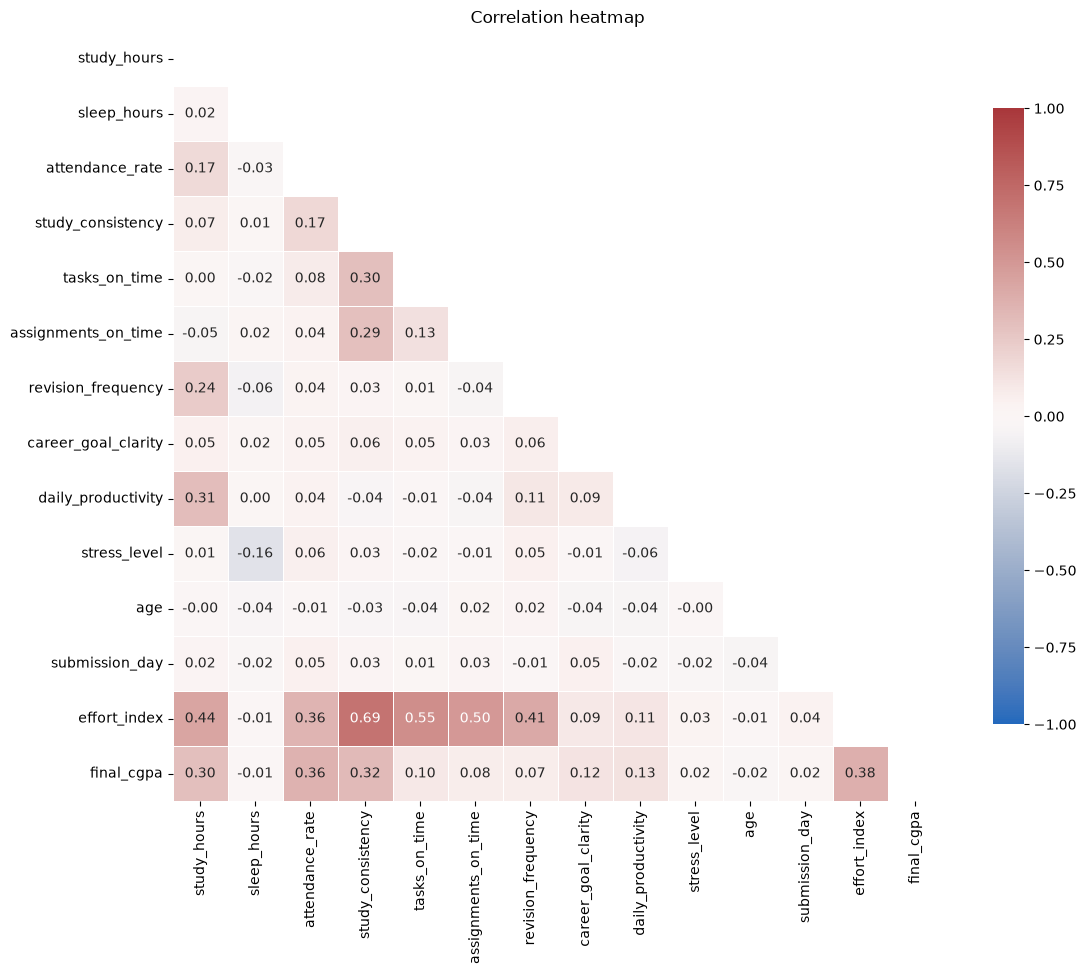

Correlation with final_cgpa (sorted):
effort_index           0.377
attendance_rate        0.365
study_consistency      0.322
study_hours            0.297
daily_productivity     0.132
career_goal_clarity    0.121
tasks_on_time          0.097
assignments_on_time    0.076
revision_frequency     0.071
submission_day         0.020
stress_level           0.019
sleep_hours           -0.010
age                   -0.024
Name: final_cgpa, dtype: float64


In [6]:
base_features = ["study_hours", "sleep_hours", "attendance_rate", "study_consistency",
                 "tasks_on_time", "assignments_on_time", "revision_frequency",
                 "career_goal_clarity", "daily_productivity", "stress_level", "age"]
features = base_features + ["submission_day"]

corr_cols = base_features + ["submission_day", "effort_index", "final_cgpa"]
corr = df[corr_cols].corr()

plt.figure(figsize=(13, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation heatmap")
plt.show()

print("Correlation with final_cgpa (sorted):")
print(corr["final_cgpa"].drop("final_cgpa").sort_values(ascending=False).round(3))

## A.4 `performance_risk_level` vs `cgpa_category`

In [7]:
print(pd.crosstab(df["cgpa_category"], df["performance_risk_level"]))
print()
print(pd.crosstab(df["cgpa_category"], df["performance_risk_level"], normalize="index").round(2))

performance_risk_level  High Risk  Low Risk  Moderate Risk
cgpa_category                                             
5.0-6.9                       188         0             48
7.0-8.4                       221         4            195
8.5-9.4                        39        89            234
9.5-10.0                        4        83             95

performance_risk_level  High Risk  Low Risk  Moderate Risk
cgpa_category                                             
5.0-6.9                      0.80      0.00           0.20
7.0-8.4                      0.53      0.01           0.46
8.5-9.4                      0.11      0.25           0.65
9.5-10.0                     0.02      0.46           0.52


## A.5 `cohort_code`

In [8]:
cohort_counts = df["cohort_code"].value_counts()
print("Categories             :", df["cohort_code"].nunique())
print("Largest / smallest     :", cohort_counts.max(), "/", cohort_counts.min())
print("Categories with < 10   :", (cohort_counts < 10).sum())
print("Students in those      :", cohort_counts[cohort_counts < 10].sum())

Categories             : 42
Largest / smallest     : 212 / 3
Categories with < 10   : 12
Students in those      : 70


## A.6 Chronological order and drift

File already in chronological order: False


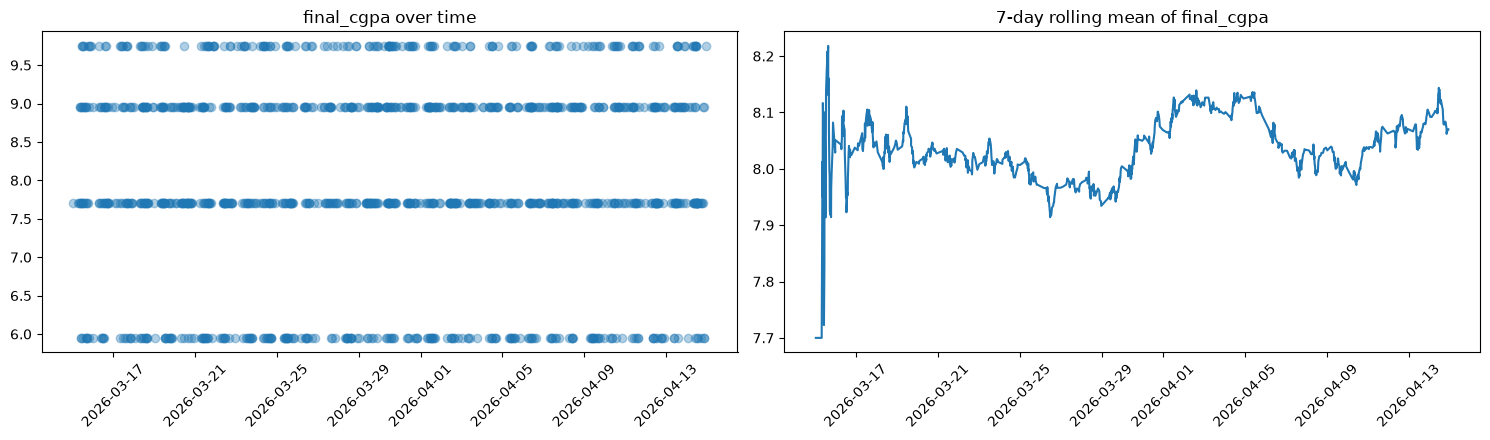

Rolling mean after the first week: min 7.91, max 8.14


In [9]:
print("File already in chronological order:", already_sorted)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ax[0].scatter(df["timestamp"], df["final_cgpa"], alpha=0.35)
ax[0].set_title("final_cgpa over time"); ax[0].tick_params(axis="x", rotation=45)

rolling = df.set_index("timestamp")["final_cgpa"].rolling("7D").mean()
ax[1].plot(rolling.index, rolling.values)
ax[1].set_title("7-day rolling mean of final_cgpa"); ax[1].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

stable = rolling[rolling.index >= T0 + pd.Timedelta(days=7)]   # skip the unstable first week
print("Rolling mean after the first week: min %.2f, max %.2f" % (stable.min(), stable.max()))

## A — Risks found
| Risk | Problem it may cause |
|---|---|
| `performance_risk_level` is tied to `cgpa_category` | target leakage (see A.4) |
| Missing values in several columns | leakage if the median is computed on all data |
| `cohort_code` is high-cardinality with rare categories | overfitting (memorising small groups) |
| Survey data can contain repeated submissions | duplicates in train and test (Part B.2) |
| Rows are not stored in time order | a random split mixes past and future (Part B.1) |

# Part B — Data leakage and evaluation strategy

In [10]:
y = df["final_cgpa"]
X = df[features]

# chronological split (df is already sorted by timestamp)
split_index = int(len(df) * 0.8)
X_train_time, X_test_time = X.iloc[:split_index], X.iloc[split_index:]
y_train_time, y_test_time = y.iloc[:split_index], y.iloc[split_index:]

# random split
X_train_rnd, X_test_rnd, y_train_rnd, y_test_rnd = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE)

print("Chronological train:", X_train_time.shape, "| test:", X_test_time.shape)
print("Train dates:", df["timestamp"].iloc[0].date(), "->", df["timestamp"].iloc[split_index - 1].date())
print("Test dates :", df["timestamp"].iloc[split_index].date(), "->", df["timestamp"].iloc[-1].date())

def make_tree(depth=None):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("tree", DecisionTreeRegressor(max_depth=depth, random_state=RANDOM_STATE))])

def evaluate_cv(model, X, y, n_splits=5):
    """Mean train / validation RMSE over TimeSeriesSplit folds."""
    tr, va = [], []
    for tr_idx, va_idx in TimeSeriesSplit(n_splits=n_splits).split(X):
        m = clone(model)
        m.fit(X.iloc[tr_idx], y.iloc[tr_idx])
        tr.append(rmse(y.iloc[tr_idx], m.predict(X.iloc[tr_idx])))
        va.append(rmse(y.iloc[va_idx], m.predict(X.iloc[va_idx])))
    return float(np.mean(tr)), float(np.mean(va))

Chronological train: (960, 12) | test: (240, 12)
Train dates: 2026-03-15 -> 2026-04-08
Test dates : 2026-04-08 -> 2026-04-14


## B.1 Random vs chronological split

In [11]:
rows = []
for name, Xtr, Xte, ytr, yte in [
        ("Random split", X_train_rnd, X_test_rnd, y_train_rnd, y_test_rnd),
        ("Chronological split", X_train_time, X_test_time, y_train_time, y_test_time)]:
    m = make_tree().fit(Xtr, ytr)
    base = DummyRegressor(strategy="mean").fit(Xtr, ytr)
    rows.append({"Strategy": name,
                 "Train RMSE": rmse(ytr, m.predict(Xtr)),
                 "Test RMSE": rmse(yte, m.predict(Xte)),
                 "Baseline RMSE": rmse(yte, base.predict(Xte))})
b1_df = pd.DataFrame(rows)
b1_df

,Strategy,Train RMSE,Test RMSE,Baseline RMSE
0,Random split,5.491584e-16,1.588143,1.338463
1,Chronological split,5.238873e-16,1.953344,1.236164


In [12]:
# How much does the random-split score move just because of the seed?
scores = []
for seed in range(20):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=seed)
    scores.append(rmse(yte, make_tree().fit(Xtr, ytr).predict(Xte)))
print("Random split, 20 seeds: mean test RMSE = %.3f, std = %.3f" % (np.mean(scores), np.std(scores)))

Random split, 20 seeds: mean test RMSE = 1.568, std = 0.071


In [13]:
# Is submission_day responsible for the large chronological error? (test days lie beyond the training range)
print("submission_day range  train: %d-%d | test: %d-%d" % (X_train_time["submission_day"].min(),
      X_train_time["submission_day"].max(), X_test_time["submission_day"].min(), X_test_time["submission_day"].max()))
no_day = [f for f in features if f != "submission_day"]
rows = []
for label, cols in [("with submission_day", features), ("without submission_day", no_day)]:
    m = make_tree().fit(X_train_time[cols], y_train_time)
    Xa, Xb, ya, yb = train_test_split(X[cols], y, test_size=0.2, random_state=RANDOM_STATE)
    mr = make_tree().fit(Xa, ya)
    rows.append({"Features": label,
                 "Chronological test RMSE": rmse(y_test_time, m.predict(X_test_time[cols])),
                 "Random test RMSE": rmse(yb, mr.predict(Xb))})
pd.DataFrame(rows)

submission_day range  train: 0-24 | test: 24-30


,Features,Chronological test RMSE,Random test RMSE
0,with submission_day,1.953344,1.588143
1,without submission_day,1.610474,1.547892


## B.2 Duplicate leakage
15 % of the rows are submitted twice (same answers and `student_id`, new random timestamp). **Both** comparisons use the chronological split (the original version used a random `train_test_split` here).

In [14]:
dup_rows = df.sample(frac=0.15, random_state=RANDOM_STATE).copy()
rng = np.random.default_rng(RANDOM_STATE)
span = int((df["timestamp"].max() - T0).total_seconds())
dup_rows["timestamp"] = T0 + pd.to_timedelta(rng.integers(0, span, size=len(dup_rows)), unit="s")
dup_rows["submission_day"] = (dup_rows["timestamp"] - T0).dt.days

df_dup = (pd.concat([df, dup_rows], ignore_index=True)
            .sort_values("timestamp").reset_index(drop=True))
print("Original:", df.shape, "| augmented:", df_dup.shape)

key_cols = [c for c in df_dup.columns if c not in ["timestamp", "submission_day"]]
print("Duplicated rows (all columns except timestamp):", df_dup.duplicated(subset=key_cols).sum())

def chrono_eval(frame, label, feats=features):
    frame = frame.sort_values("timestamp").reset_index(drop=True)
    k = int(len(frame) * 0.8)
    tr, te = frame.iloc[:k], frame.iloc[k:]
    m = make_tree().fit(tr[feats], tr["final_cgpa"])
    base = DummyRegressor().fit(tr[feats], tr["final_cgpa"])
    keys = frame[key_cols].apply(lambda r: "|".join(map(str, r)), axis=1)
    leaked = int(keys.iloc[k:].isin(set(keys.iloc[:k])).sum())
    return {"Strategy": label, "n_train": len(tr), "n_test": len(te),
            "Train RMSE": rmse(tr["final_cgpa"], m.predict(tr[feats])),
            "Test RMSE": rmse(te["final_cgpa"], m.predict(te[feats])),
            "Baseline RMSE": rmse(te["final_cgpa"], base.predict(te[feats])),
            "Test rows also in train": leaked}

df_nodup = df_dup.drop_duplicates(subset=key_cols, keep="first")   # df_dup is sorted: keeps the earliest copy
b2_df = pd.DataFrame([
    chrono_eval(df_dup,   "Split first, duplicates kept"),
    chrono_eval(df_nodup, "Remove duplicates, then split"),
    chrono_eval(df_dup,   "Split first, duplicates kept (no submission_day)", no_day),
    chrono_eval(df_nodup, "Remove duplicates, then split (no submission_day)", no_day),
])
b2_df

Original: (1200, 42) | augmented: (1380, 42)
Duplicated rows (all columns except timestamp): 180


,Strategy,n_train,n_test,Train RMSE,Test RMSE,Baseline RMSE,Test rows also in train
0,"Split first, duplicates kept",1104,276,5.788981e-16,1.712758,1.229768,52
1,"Remove duplicates, then split",960,240,5.223164e-16,1.690691,1.209962,0
2,"Split first, duplicates kept (no submission_day)",1104,276,7.391271e-02,1.281396,1.229768,52
3,"Remove duplicates, then split (no submission_day)",960,240,7.926255e-02,1.579083,1.209962,0


## B.3 Preprocessing leakage (KNN, k = 10)

In [15]:
# WRONG: median and scaler learned on the whole dataset (train + test)
imp_all = SimpleImputer(strategy="median").fit(X)
sc_all = StandardScaler().fit(imp_all.transform(X))
knn_wrong = KNeighborsRegressor(n_neighbors=10).fit(
    sc_all.transform(imp_all.transform(X_train_time)), y_train_time)
rmse_wrong = rmse(y_test_time, knn_wrong.predict(sc_all.transform(imp_all.transform(X_test_time))))

# CORRECT: everything fitted on the training data only, inside a Pipeline
knn_ok = Pipeline([("imputer", SimpleImputer(strategy="median")),
                   ("scaler", StandardScaler()),
                   ("knn", KNeighborsRegressor(n_neighbors=10))]).fit(X_train_time, y_train_time)
rmse_ok = rmse(y_test_time, knn_ok.predict(X_test_time))

b3_df = pd.DataFrame({"Strategy": ["Imputer + scaler fitted on all data", "Pipeline (train only)"],
                      "Test RMSE": [rmse_wrong, rmse_ok]})
b3_df

,Strategy,Test RMSE
0,Imputer + scaler fitted on all data,1.149634
1,Pipeline (train only),1.145366


# Part C — Diagnosing overfitting

## C.1 Tree depth
Train/test RMSE and gap as the worksheet asks, plus the `TimeSeriesSplit` validation RMSE (used later to *choose* a depth without touching the test set).

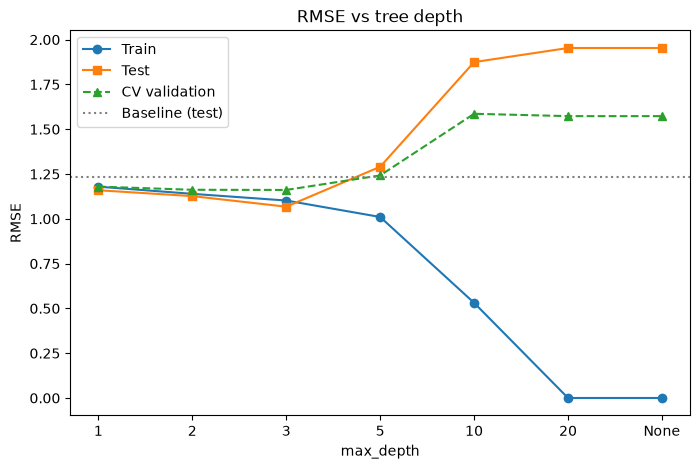

,max_depth,Train RMSE,Test RMSE,Gap (test - train),CV validation RMSE
0,1,1.179373e+00,1.159411,-0.019962,1.179903
1,2,1.139418e+00,1.126782,-0.012636,1.161991
2,3,1.102091e+00,1.067666,-0.034425,1.161146
3,5,1.010248e+00,1.290498,0.280250,1.242270
4,10,5.311170e-01,1.874668,1.343551,1.586204
5,20,5.238873e-16,1.953344,1.953344,1.573078
6,None,5.238873e-16,1.953344,1.953344,1.573078


In [16]:
depths = [1, 2, 3, 5, 10, 20, None]
rows = []
for d in depths:
    m = make_tree(d).fit(X_train_time, y_train_time)
    tr, te = rmse(y_train_time, m.predict(X_train_time)), rmse(y_test_time, m.predict(X_test_time))
    _, cv_val = evaluate_cv(make_tree(d), X_train_time, y_train_time)
    rows.append({"max_depth": "None" if d is None else d,
                 "Train RMSE": tr, "Test RMSE": te, "Gap (test - train)": te - tr,
                 "CV validation RMSE": cv_val})
c1_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 5))
xs = range(len(depths))
plt.plot(xs, c1_df["Train RMSE"], "o-", label="Train")
plt.plot(xs, c1_df["Test RMSE"], "s-", label="Test")
plt.plot(xs, c1_df["CV validation RMSE"], "^--", label="CV validation")
plt.axhline(rmse(y_test_time, DummyRegressor().fit(X_train_time, y_train_time).predict(X_test_time)),
            color="gray", ls=":", label="Baseline (test)")
plt.xticks(list(xs), c1_df["max_depth"].astype(str))
plt.xlabel("max_depth"); plt.ylabel("RMSE"); plt.title("RMSE vs tree depth"); plt.legend(); plt.show()
c1_df

## C.2 Polynomial degree of `effort_index`
Only `effort_index` is expanded (the original code expanded all 12 features).

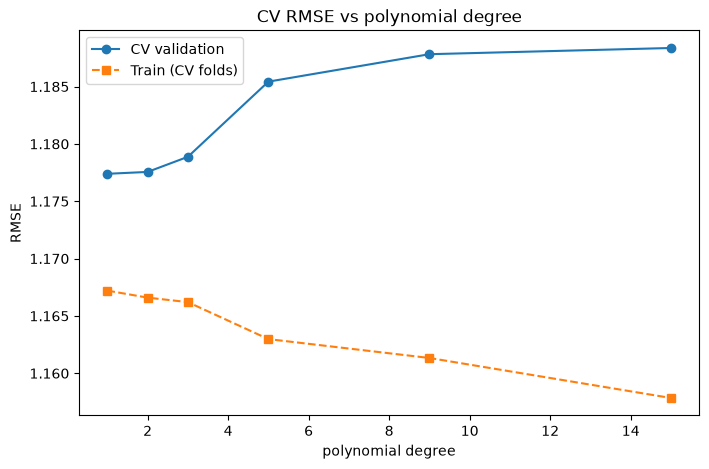

,degree,Train RMSE (CV),CV validation RMSE
0,1,1.167207,1.177394
1,2,1.166596,1.177557
2,3,1.166203,1.178874
3,5,1.162978,1.185431
4,9,1.161332,1.187823
5,15,1.157843,1.188364


In [17]:
X_effort_train = df.loc[X_train_time.index, ["effort_index"]]

def poly_model(estimator, degree):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("poly", PolynomialFeatures(degree=degree, include_bias=False)),
                     ("scaler", StandardScaler()),
                     ("model", estimator)])

degrees = [1, 2, 3, 5, 9, 15]
rows = []
for deg in degrees:
    tr, va = evaluate_cv(poly_model(LinearRegression(), deg), X_effort_train, y_train_time)
    rows.append({"degree": deg, "Train RMSE (CV)": tr, "CV validation RMSE": va})
c2_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 5))
plt.plot(c2_df["degree"], c2_df["CV validation RMSE"], "o-", label="CV validation")
plt.plot(c2_df["degree"], c2_df["Train RMSE (CV)"], "s--", label="Train (CV folds)")
plt.xlabel("polynomial degree"); plt.ylabel("RMSE"); plt.title("CV RMSE vs polynomial degree")
plt.legend(); plt.show()
c2_df

# Part D — Improving generalization (validation only; the test set is not used until D.4)

## D.1 `cohort_code`

In [18]:
X_train_d1 = X_train_time.copy()
X_train_d1["cohort_code"] = df.loc[X_train_time.index, "cohort_code"]

def cohort_model(approach):
    if approach == "Feature removal":
        return make_tree(5)
    enc = (OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist", sparse_output=False)
           if approach == "Rare-category grouping" else TargetEncoder(cv=5, shuffle=False))
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), features),
                             ("cohort", enc, ["cohort_code"])])
    return Pipeline([("pre", pre), ("tree", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))])

rows = []
for approach in ["Rare-category grouping", "Target encoding", "Feature removal"]:
    X_used = X_train_time if approach == "Feature removal" else X_train_d1
    tr, va = evaluate_cv(cohort_model(approach), X_used, y_train_time)
    rows.append({"Approach": approach, "Train RMSE": tr, "Validation RMSE": va})
d1_df = pd.DataFrame(rows).sort_values("Validation RMSE").reset_index(drop=True)
cohort_choice = {"Rare-category grouping": "rare", "Target encoding": "target",
                 "Feature removal": "remove"}[d1_df.loc[0, "Approach"]]
print("Selected treatment:", d1_df.loc[0, "Approach"])
d1_df

Selected treatment: Rare-category grouping


,Approach,Train RMSE,Validation RMSE
0,Rare-category grouping,0.871332,1.221146
1,Feature removal,0.878703,1.242270
2,Target encoding,0.963932,1.260481


## D.2 Keep `submission_day`?

In [19]:
features_no_day = [f for f in features if f != "submission_day"]

def d2_models():
    imp = lambda: ("imputer", SimpleImputer(strategy="median"))
    return {
        "Linear Regression": Pipeline([imp(), ("model", LinearRegression())]),
        "Decision Tree": Pipeline([imp(), ("model", DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE))]),
        "Gradient Boosting": Pipeline([imp(), ("model", GradientBoostingRegressor(
            n_estimators=60, learning_rate=0.05, max_depth=3, random_state=RANDOM_STATE))]),
    }

rows = []
for name, model in d2_models().items():
    _, v_with = evaluate_cv(model, X_train_time[features], y_train_time)
    _, v_without = evaluate_cv(model, X_train_time[features_no_day], y_train_time)
    rows.append({"Model": name, "Val RMSE with day": v_with, "Val RMSE without day": v_without,
                 "Difference (with - without)": v_with - v_without})
d2_df = pd.DataFrame(rows)

# rule: keep the feature only if it lowers the validation RMSE for ALL three models
keep_submission_day = bool((d2_df["Difference (with - without)"] < 0).all())
print("keep_submission_day =", keep_submission_day)
d2_df

keep_submission_day = False


,Model,Val RMSE with day,Val RMSE without day,Difference (with - without)
0,Linear Regression,1.126312,1.118184,0.008128
1,Decision Tree,1.242270,1.201511,0.040759
2,Gradient Boosting,1.129088,1.127468,0.001620


## D.3 Regularisation on a degree-5 polynomial of `effort_index`

In [20]:
alphas = [0.001, 0.01, 0.1, 1, 10, 100]
rows = []
tr, va = evaluate_cv(poly_model(LinearRegression(), 5), X_effort_train, y_train_time)
rows.append({"Model": "Linear", "Alpha": np.nan, "Train RMSE": tr, "Validation RMSE": va})
for name, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        tr, va = evaluate_cv(poly_model(cls(alpha=a, max_iter=100000), 5), X_effort_train, y_train_time)
        rows.append({"Model": name, "Alpha": a, "Train RMSE": tr, "Validation RMSE": va})
d3_df = pd.DataFrame(rows)
d3_df

,Model,Alpha,Train RMSE,Validation RMSE
0,Linear,NaN,1.162978,1.185431
1,Ridge,0.001,1.165600,1.180825
2,Ridge,0.010,1.165867,1.179978
3,Ridge,0.100,1.166091,1.179002
4,Ridge,1.000,1.166244,1.178429
5,Ridge,10.000,1.166863,1.178185
6,Ridge,100.000,1.172034,1.180543
7,Lasso,0.001,1.166346,1.178131
8,Lasso,0.010,1.166960,1.177130
9,Lasso,0.100,1.171484,1.177237


In [21]:
best_alpha = {m: d3_df[d3_df.Model == m].sort_values("Validation RMSE").iloc[0]["Alpha"]
              for m in ["Ridge", "Lasso"]}
print("Best alpha:", best_alpha)

coef_rows = []
for name, est in [("Linear", LinearRegression()),
                  ("Ridge", Ridge(alpha=best_alpha["Ridge"])),
                  ("Lasso", Lasso(alpha=best_alpha["Lasso"], max_iter=100000))]:
    m = poly_model(est, 5).fit(X_effort_train, y_train_time)
    c = m.named_steps["model"].coef_
    coef_rows.append({"Model": name, "Coefficients": len(c), "Exactly zero": int(np.sum(c == 0)),
                      "Max |coef|": float(np.abs(c).max()), "Sum |coef|": float(np.abs(c).sum())})
pd.DataFrame(coef_rows)

Best alpha: {'Ridge': np.float64(10.0), 'Lasso': np.float64(0.01)}


,Model,Coefficients,Exactly zero,Max |coef|,Sum |coef|
0,Linear,5,0,66.182608,181.042285
1,Ridge,5,0,0.394120,0.662863
2,Lasso,5,4,0.470968,0.470968


## D.4 Final comparison on the untouched test set

In [22]:
final_features = features if keep_submission_day else features_no_day
final_cols = final_features + (["cohort_code"] if cohort_choice != "remove" else [])
print("cohort_choice =", cohort_choice, "| keep_submission_day =", keep_submission_day)

X_final_train = df.loc[X_train_time.index, final_cols]
X_final_test = df.loc[X_test_time.index, final_cols]

def make_pre():
    tf = [("num", SimpleImputer(strategy="median"), final_features)]
    if cohort_choice == "rare":
        tf.append(("cohort", OneHotEncoder(min_frequency=10, handle_unknown="infrequent_if_exist",
                                           sparse_output=False), ["cohort_code"]))
    elif cohort_choice == "target":
        tf.append(("cohort", TargetEncoder(cv=5, shuffle=False), ["cohort_code"]))
    return ColumnTransformer(tf)

def linear_pipe(est):
    return Pipeline([("pre", make_pre()), ("scaler", StandardScaler()), ("model", est)])

# Ridge / Lasso: alpha chosen with TimeSeriesSplit (no polynomial expansion)
rows = []
for name, cls in [("Ridge", Ridge), ("Lasso", Lasso)]:
    for a in alphas:
        _, va = evaluate_cv(linear_pipe(cls(alpha=a, max_iter=100000)), X_final_train, y_train_time)
        rows.append({"Model": name, "Alpha": a, "Validation RMSE": va})
d4_reg = pd.DataFrame(rows).sort_values("Validation RMSE").reset_index(drop=True)
best_reg = d4_reg.iloc[0]
reg_cls = Ridge if best_reg["Model"] == "Ridge" else Lasso
print("Selected:", best_reg["Model"], "alpha =", best_reg["Alpha"])

# Decision tree: depth chosen with TimeSeriesSplit among the C.1 values
rows = []
for d in depths:
    tree = Pipeline([("pre", make_pre()), ("tree", DecisionTreeRegressor(max_depth=d, random_state=RANDOM_STATE))])
    _, va = evaluate_cv(tree, X_final_train, y_train_time)
    rows.append({"max_depth": d, "Validation RMSE": va})
d4_tree = pd.DataFrame(rows)
best_depth = d4_tree.loc[d4_tree["Validation RMSE"].idxmin(), "max_depth"]
best_depth = None if pd.isna(best_depth) else int(best_depth)
print("Selected max_depth:", best_depth)

cohort_choice = rare | keep_submission_day = False
Selected: Lasso alpha = 0.1
Selected max_depth: 3


Best number of trees: 135 | validation RMSE: 1.0754


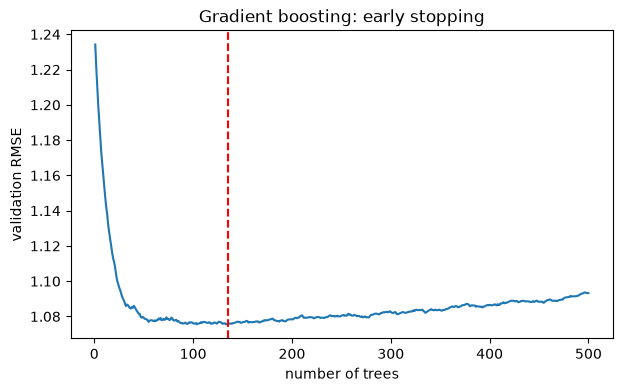

In [23]:
# Gradient boosting with chronological early stopping
k = int(len(X_final_train) * 0.85)
Xg_tr, Xg_va = X_final_train.iloc[:k], X_final_train.iloc[k:]
yg_tr, yg_va = y_train_time.iloc[:k], y_train_time.iloc[k:]

pre_gb = make_pre()
Xg_tr_t = pre_gb.fit_transform(Xg_tr, yg_tr)
Xg_va_t = pre_gb.transform(Xg_va)

gb_probe = GradientBoostingRegressor(n_estimators=500, learning_rate=0.05, max_depth=3,
                                     random_state=RANDOM_STATE).fit(Xg_tr_t, yg_tr)
val_curve = [rmse(yg_va, p) for p in gb_probe.staged_predict(Xg_va_t)]
best_n = int(np.argmin(val_curve)) + 1
print("Best number of trees:", best_n, "| validation RMSE: %.4f" % min(val_curve))

plt.figure(figsize=(7, 4)); plt.plot(range(1, 501), val_curve)
plt.axvline(best_n, color="red", ls="--"); plt.xlabel("number of trees"); plt.ylabel("validation RMSE")
plt.title("Gradient boosting: early stopping"); plt.show()

In [24]:
final_models = {
    "Baseline (training mean)": DummyRegressor(strategy="mean"),
    "Linear Regression": linear_pipe(LinearRegression()),
    f"{best_reg['Model']} (alpha={best_reg['Alpha']})": linear_pipe(reg_cls(alpha=best_reg["Alpha"], max_iter=100000)),
    f"Decision Tree (depth={best_depth})": Pipeline([("pre", make_pre()),
        ("tree", DecisionTreeRegressor(max_depth=best_depth, random_state=RANDOM_STATE))]),
    f"Gradient Boosting ({best_n} trees)": Pipeline([("pre", make_pre()),
        ("gb", GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.05, max_depth=3,
                                         random_state=RANDOM_STATE))]),
}
rows = []
for name, model in final_models.items():
    model.fit(X_final_train, y_train_time)
    p_tr, p_te = model.predict(X_final_train), model.predict(X_final_test)
    rows.append({"Model": name,
                 "Training RMSE": rmse(y_train_time, p_tr),
                 "Testing RMSE": rmse(y_test_time, p_te),
                 "Gap": rmse(y_test_time, p_te) - rmse(y_train_time, p_tr),
                 "Testing R²": r2_score(y_test_time, p_te)})
final_df = pd.DataFrame(rows)
final_df

,Model,Training RMSE,Testing RMSE,Gap,Testing R²
0,Baseline (training mean),1.268541,1.236164,-0.032378,-0.002862
1,Linear Regression,1.071666,1.085278,0.013612,0.227015
2,Lasso (alpha=0.1),1.106412,1.072085,-0.034327,0.245693
3,Decision Tree (depth=3),1.102091,1.067666,-0.034425,0.251900
4,Gradient Boosting (135 trees),0.955384,1.059266,0.103882,0.263625


# Final discussion
Test set: last 20 % (240 students, 8-14 April). Baseline (training mean) RMSE = 1.236.

**1. Best generalisation.** Gradient boosting (135 trees) has the lowest test RMSE (1.059, R² = 0.264). The depth-3 tree (1.068) and Lasso (1.072) are within 0.013 of it, which is too small to separate them, so the simple models are almost as good. All of them beat the baseline by about 0.17 RMSE.

**2. Largest generalisation gap.** Among the final models, gradient boosting (test - train = +0.104). The unrestricted tree of B.1/C.1 is far worse (train RMSE ~ 0, test 1.95). A slightly negative gap (shallow tree, Lasso, baseline) means the test period is a little easier than the training period; it is not a sign of a better model.

**3. Most effective techniques.** Limiting the tree depth (test RMSE 1.95 -> 1.07), removing `submission_day` (a feature whose test values lie outside the training range), and early stopping for boosting. Ridge/Lasso shrank the degree-5 coefficients (max |coef| 66 -> 0.4) but improved validation RMSE by only 0.007, because one feature with few distinct values cannot overfit much.

**4. Validation, not training.** Training error rewards memorisation (an unlimited tree has RMSE ~ 0 and is worse than the baseline). Validation error measures performance on rows the model did not fit, so it picks the complexity that generalises.

**5. Untouched test set.** Each time a choice is made after looking at the test score, information from the test set leaks into the model. The final test score then becomes an optimistic estimate instead of an honest one.

**6. Modest R².** The survey features explain only about a quarter of the variance of the target: answers are self-reported, coarse (ranges), and the target is a band midpoint with only 4 values. A high score is not automatically good: leakage (`performance_risk_level`, duplicates, preprocessing on all data) can inflate it without any real predictive power.